In [66]:
from typing import List
from flow_models import OpticalFlowModel
import matplotlib.pyplot as plt
import torch
import cv2
import numpy as np
from utils.loss_utils import ssim
from tqdm import tqdm
import torch.nn.functional as F
from PIL import Image
import os

model_list = [
    # ("flowseek_m", "tar-c-t"),
    # ("raft", "things"),
    # ("gmflow", "things"),
    # ("sea_raft_m", "things"),
    # ("sea_raft_m", "sintel"),
    ("unimatch_sc2_ref6", "mix")
]

# model_name = 'flowseek_m'
# model_ckpt = 'tar-c-t'

# model_name = 'raft'
# model_ckpt = 'things'

# model_name = 'gmflow'
# model_ckpt = 'things'

# model = OpticalFlowModel(model_name, model_ckpt)
# model = ptlflow.get_model('flowseek_m', ckpt_path='tar-c-t-tskh')

# model = ptlflow.get_model('waft_dinov3_a2', ckpt_path='zero_shot')
# model = ptlflow.get_model('waft_dav2_a1', ckpt_path='tar-c-t')
# model = ptlflow.get_model('waft_dav2_a1', ckpt_path='tar-c-t-sintel')
# model = ptlflow.get_model('dpflow', ckpt_path='sintel')
# model = ptlflow.get_model('gmflow', ckpt_path='things')
# model = ptlflow.get_model('unimatch_sc2_ref6', ckpt_path='mix')
# model = ptlflow.get_model('unimatch_sc2', ckpt_path='mix')

In [44]:
def warp_image(img: torch.Tensor, flow: torch.Tensor) -> torch.Tensor:
    """
    Warp target image to source coordinates using optical flow.

    Equivalent to:
        warped(x, y) = img(x + flow_x, y + flow_y)

    Args:
        img:
            Target image, shape [1, 3, H, W], values in [0, 1].

        flow:
            Optical flow from source -> target,
            shape [H, W, 2], in pixel units.

            flow[..., 0] = dx
            flow[..., 1] = dy

    Returns:
        warped_img:
            Shape [1, 3, H, W].
    """
    _, _, H, W = img.shape
    device = img.device
    dtype = img.dtype

    # [H, W]
    y, x = torch.meshgrid(
        torch.arange(H, device=device, dtype=dtype),
        torch.arange(W, device=device, dtype=dtype),
        indexing="ij",
    )

    # Source pixel + optical flow -> corresponding target pixel
    sample_x = x + flow[..., 0]
    sample_y = y + flow[..., 1]

    # grid_sample expects coordinates in [-1, 1]
    sample_x = 2.0 * sample_x / (W - 1) - 1.0
    sample_y = 2.0 * sample_y / (H - 1) - 1.0

    # [1, H, W, 2]
    grid = torch.stack([sample_x, sample_y], dim=-1).unsqueeze(0)
    warped_img = F.grid_sample(img, grid, mode="bilinear", padding_mode="zeros", align_corners=True)

    return warped_img


@torch.no_grad()
def evaluate_flow_consistency(
    frame_a: torch.Tensor,
    frame_b: torch.Tensor,
    flow_a_to_b: torch.Tensor,
) -> torch.Tensor:
    """
    Evaluate optical-flow consistency for one direction.

    Args:
        frame_a:
            Source image [1, 3, H, W], values [0, 1].

        frame_b:
            Target image [1, 3, H, W], values [0, 1].

        flow_a_to_b:
            Flow A -> B, shape [H, W, 2].

    Returns:
        Scalar SSIM tensor.
    """
    warped_b = warp_image(frame_b, flow_a_to_b)
    score = ssim(frame_a, warped_b)

    return score, (frame_a, warped_b)


@torch.no_grad()
def evaluate_frame_list(
    frames: List[torch.Tensor],
    flow_model,
    device: str = "cuda") -> float:
    """
    Evaluate optical-flow consistency over consecutive frame pairs.

    For each pair (frame_t, frame_{t+1}):

        1. Predict forward flow:
               frame_t -> frame_{t+1}

        2. Warp frame_{t+1} back to frame_t
           and calculate SSIM.

        3. Predict backward flow:
               frame_{t+1} -> frame_t

        4. Warp frame_t back to frame_{t+1}
           and calculate SSIM.

    Final score:
        mean of all forward and backward SSIM scores.

    Args:
        frames:
            List of images.
            Each image has shape [1, 3, H, W],
            values in [0, 1].

        flow_model:
            Callable:

                flow = flow_model(image1, image2)

            Input:
                image1: [3, H, W]
                image2: [3, H, W]

            Output:
                flow: [H, W, 2]

        device:
            CUDA device, e.g.:
                "cuda"
                "cuda:0"

    Returns:
        Mean forward/backward SSIM score as Python float.
    """
    if len(frames) < 2:
        raise ValueError("At least 2 frames are required.")

    scores = []
    pairs = []

    for i in tqdm(range(len(frames) - 1)):
        frame_a = frames[i].to(device)
        frame_b = frames[i + 1].to(device)

        flow_a_to_b = flow_model.forward(frame_a[0], frame_b[0])
        forward_score, forward_pair = evaluate_flow_consistency(frame_a, frame_b, flow_a_to_b)

        flow_b_to_a = flow_model.forward(frame_b[0], frame_a[0])
        backward_score, backward_pair = evaluate_flow_consistency(frame_b, frame_a, flow_b_to_a)

        scores.append(forward_score)
        scores.append(backward_score)
        pairs.append(forward_pair)
        pairs.append(backward_pair)

    scores = torch.stack(scores)
    return scores.mean().item(), pairs

@torch.no_grad()
def evaluate_from_dir(dir_path: str, flow_model, device: str = "cuda") -> float:
    """
    Evaluate optical-flow consistency over consecutive frame pairs.

    Args:
        dir_path:
            Directory containing images.

        flow_model:
            Callable:

                flow = flow_model(image1, image2)

            Input:
                image1: [3, H, W]
                image2: [3, H, W]

            Output:
                flow: [H, W, 2]

        device:
            CUDA device, e.g.:
                "cuda"
                "cuda:0"

    Returns:
        Mean forward/backward SSIM score as Python float.
    """
    import os

    # Get all image files in the directory
    image_files = sorted(
        [
            f for f in os.listdir(dir_path)
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp'))
        ]
    )

    print(f"Found {len(image_files)} images in {dir_path}")

    # Read images and convert to tensors
    frames = []
    for img_file in tqdm(image_files, desc="Reading images"):
        img_path = os.path.join(dir_path, img_file)
        img = read_image(img_path).to(device)
        frames.append(img)

    return evaluate_frame_list(frames, flow_model, device=device)

In [45]:
def read_image(image_path):
    image = np.array(Image.open(image_path))
    image = (torch.from_numpy(image).float() / 255.0).permute(2, 0, 1)
    image = image.unsqueeze(0) # (1, 3, H, W)
    return image

data_root = "/network-volume/nhphuc/dataset"
images_path = f"{data_root}/stereomis/p3_9100_368_s4/images"
# image1_path = f"{images_path}/009100.png"
# image2_path = f"{images_path}/009108.png"
# image3_path = f"{images_path}/009116.png"

# Load the images
images = [read_image(os.path.join(images_path, img)).cuda() for img in os.listdir(images_path) if img.endswith(('.png', '.jpg', '.jpeg', '.bmp'))]

In [46]:
for model_arg in model_list:
    model = OpticalFlowModel(*model_arg)
    score, pairs = evaluate_frame_list(images, model, device="cuda")
    print(f"{model_arg[0]} ({model_arg[1]}): {score}")

2026-08-19 15:32:14.310 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: tar-c-t
100%|██████████| 91/91 [00:36<00:00,  2.51it/s]
2026-08-19 15:32:50.824 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: things


flowseek_m (tar-c-t): 0.8624797463417053


100%|██████████| 91/91 [00:27<00:00,  3.26it/s]
2026-08-19 15:33:18.939 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: things


raft (things): 0.8578183054924011


100%|██████████| 91/91 [00:08<00:00, 11.29it/s]

gmflow (things): 0.8490899205207825


In [49]:
for model_arg in model_list:
    model = OpticalFlowModel(*model_arg)
    score, pairs = evaluate_frame_list(images, model, device="cuda")
    print(f"{model_arg[0]} ({model_arg[1]}): {score}")

Downloading: "https://github.com/hmorimitsu/ptlflow/releases/download/weights1/sea_raft_m-things-ac45dd7f.ckpt" to /root/.cache/torch/hub/checkpoints/sea_raft_m-things-ac45dd7f.ckpt
100%|██████████| 75.2M/75.2M [00:06<00:00, 12.4MB/s]
2026-08-19 15:40:52.906 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: things
100%|██████████| 91/91 [00:07<00:00, 11.44it/s]

sea_raft_m (things): 0.8495041131973267


In [51]:
for model_arg in model_list:
    model = OpticalFlowModel(*model_arg)
    score, pairs = evaluate_frame_list(images, model, device="cuda")
    print(f"{model_arg[0]} ({model_arg[1]}): {score}")

Downloading: "https://github.com/hmorimitsu/ptlflow/releases/download/weights1/sea_raft_m-sintel-f8bb7e3f.ckpt" to /root/.cache/torch/hub/checkpoints/sea_raft_m-sintel-f8bb7e3f.ckpt
100%|██████████| 75.2M/75.2M [00:06<00:00, 12.3MB/s]
2026-08-19 15:42:40.650 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: sintel
100%|██████████| 91/91 [00:07<00:00, 11.46it/s]

sea_raft_m (sintel): 0.8636173009872437


In [67]:
for model_arg in model_list:
    model = OpticalFlowModel(*model_arg)
    score, pairs = evaluate_frame_list(images, model, device="cuda")
    print(f"{model_arg[0]} ({model_arg[1]}): {score}")

2026-08-19 16:24:56.964 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: mix
100%|██████████| 91/91 [01:31<00:00,  1.01s/it]

unimatch_sc2_ref6 (mix): 0.8598037958145142


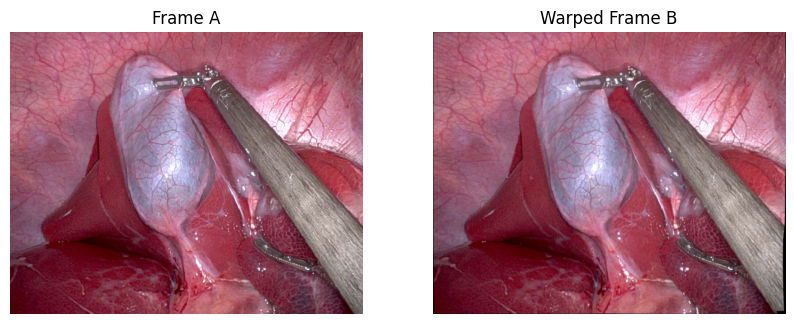

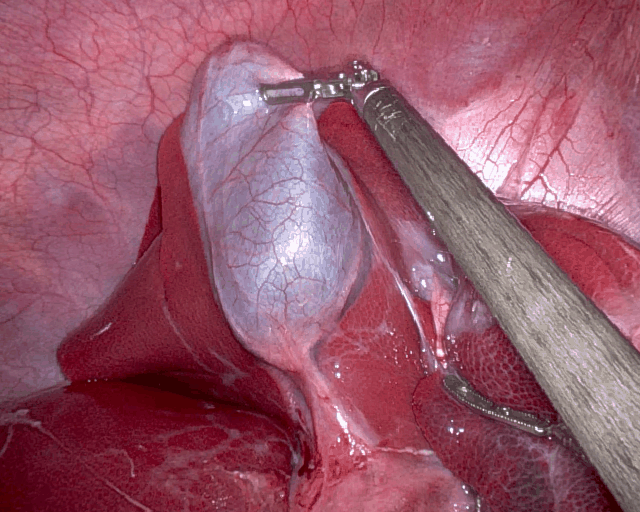

In [65]:
pair = pairs[1]  # Get the first pair of images (frame_a, warped_b)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(pair[0].squeeze(0).permute(1, 2, 0).cpu().numpy())
plt.title("Frame A")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pair[1].squeeze(0).permute(1, 2, 0).cpu().numpy())
plt.title("Warped Frame B")
plt.axis("off")
plt.show()

# create GIF animation of the warped images
warped_images = [pair[0], pair[1]]  # List of images to include in the GIF
warped_images = [img.squeeze(0).permute(1, 2, 0).cpu().numpy() for img in warped_images]  # Convert to numpy arrays
warped_images = [Image.fromarray((img * 255).astype(np.uint8)) for img in warped_images]  # Convert to PIL Images
warped_images[0].save("tmp/warped_animation.gif", save_all=True, append_images=warped_images[1:], duration=500, loop=0)  # Save as GIF
# Show the GIF animation
from IPython.display import Image as IPImage, display
display(IPImage(filename="tmp/warped_animation.gif"))